In [16]:
import pandas as pd

In [17]:
orders = pd.read_csv('https://raw.githubusercontent.com/suraiyabinteakbar/food-delivery-hourly-demand-analytics/main/data/sample_orders.csv')
orders.head()

,Order ID,Order Date,Restaurant Branch ID,Restaurant Name,Customer ID,Rider ID,Order Status,Order Type,Total Amount,Branch Zone,...,Discount Amount,Promo Code,Restaurant Commission,Platform Subsidy,Restaurant Subsidy Share,Rider Earning,Avg Delivery Time Min,Delivery Status,Month Name,Date
0,ORD100000,2026-02-01 11:27:46,10206,Sushi Circle - Lakeside,CUST06558,RDR-0365,delivered,delivery,1061.75,Lakeside,...,100,WELCOME10,265.44,0.00,0.00,40,22,True,February,2026-02-01
1,ORD100001,2026-05-06 16:40:08,10128,Charcoal Chicken House - Stadium Area,CUST00439,RDR-0184,delivered,delivery,1369.59,Stadium Area,...,100,NaN,272.55,0.00,0.00,80,46,True,May,2026-05-06
2,ORD100002,2026-04-30 11:42:31,10405,Rolls & Wraps Co - Cultural Quarter,CUST08956,RDR-0019,delivered,pickup,259.15,Cultural Quarter,...,100,WELCOME10,55.98,0.00,0.00,70,44,True,April,2026-04-30
3,ORD100003,2026-01-09 10:42:55,10018,The Breakfast Table - Lakeside,CUST05120,RDR-0733,cancelled,delivery,563.55,Lakeside,...,30,WELCOME10,74.95,0.00,0.00,70,50,False,January,2026-01-09
4,ORD100004,2026-02-10 16:25:16,10437,Sushi Circle - Cultural Quarter,CUST05716,RDR-0829,delivered,delivery,306.65,Cultural Quarter,...,0,NaN,75.74,20.53,6.16,70,37,True,February,2026-02-10


In [18]:
print(orders.shape)
print(orders.columns)


(25000, 25)
Index(['Order ID', 'Order Date', 'Restaurant Branch ID', 'Restaurant Name',
       'Customer ID', 'Rider ID', 'Order Status', 'Order Type', 'Total Amount',
       'Branch Zone', 'Delivery Zone', 'Payment Method', 'Payment Gateway',
       'Payment Status', 'Delivery Charge', 'Discount Amount', 'Promo Code',
       'Restaurant Commission', 'Platform Subsidy', 'Restaurant Subsidy Share',
       'Rider Earning', 'Avg Delivery Time Min', 'Delivery Status',
       'Month Name', 'Date'],
      dtype='object')


In [19]:
print(orders['Order Date'].dtype)

object


In [20]:
orders['Order Date'] = pd.to_datetime(orders['Order Date'])
print(orders['Order Date'].dtype)

datetime64[ns]


In [21]:
orders['Hour'] = orders['Order Date'].dt.hour
orders[['Order Date', 'Hour']].head()

,Order Date,Hour
0,2026-02-01 11:27:46,11
1,2026-05-06 16:40:08,16
2,2026-04-30 11:42:31,11
3,2026-01-09 10:42:55,10
4,2026-02-10 16:25:16,16


In [22]:
hourly_counts = orders.groupby('Hour').size()
print(hourly_counts)

Hour
0      178
1      145
2      152
3      176
4      171
5      181
6      327
7      493
8      698
9      918
10     997
11    1799
12    2405
13    1677
14    1007
15     908
16    1047
17    1377
18    1662
19    2386
20    2719
21    2036
22    1065
23     476
dtype: int64


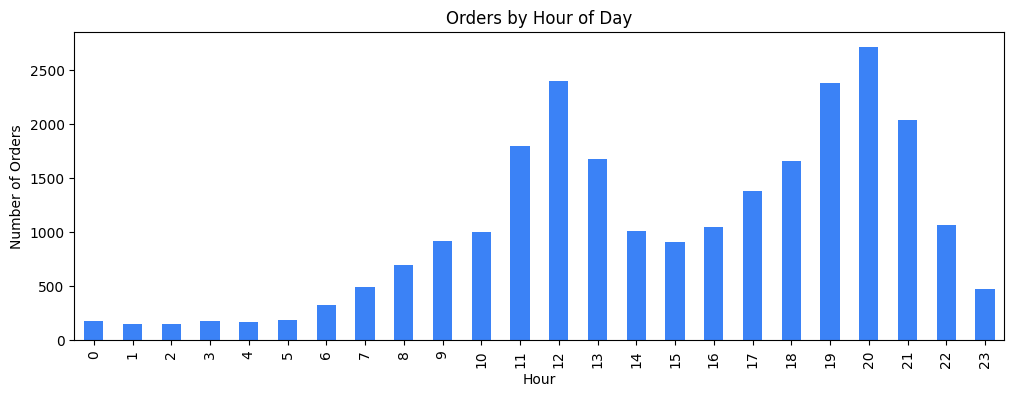

In [23]:
import matplotlib.pyplot as plt

hourly_counts.plot(kind='bar', figsize=(12,4), color='#3b82f6', title='Orders by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Number of Orders')
plt.show()

In [24]:
orders['Weekday'] = orders['Order Date'].dt.day_name()
weekday_counts = orders.groupby('Weekday').size()
print(weekday_counts)

Weekday
Friday       3654
Monday       3479
Saturday     3547
Sunday       3620
Thursday     3675
Tuesday      3466
Wednesday    3559
dtype: int64


In [25]:
orders['DateHour'] = orders['Order Date'].dt.floor('H')
hourly_series = orders.groupby('DateHour').size().reset_index(name='OrderCount')
hourly_series.head(10)

/tmp/ipykernel_614/1082994065.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  orders['DateHour'] = orders['Order Date'].dt.floor('H')


,DateHour,OrderCount
0,2026-01-01 00:00:00,1
1,2026-01-01 03:00:00,2
2,2026-01-01 04:00:00,2
3,2026-01-01 05:00:00,2
4,2026-01-01 06:00:00,4
5,2026-01-01 07:00:00,4
6,2026-01-01 08:00:00,5
7,2026-01-01 09:00:00,10
8,2026-01-01 10:00:00,3
9,2026-01-01 11:00:00,7


In [26]:
hourly_series['Hour'] = hourly_series['DateHour'].dt.hour
hourly_series['Weekday'] = hourly_series['DateHour'].dt.dayofweek
hourly_series['IsWeekend'] = hourly_series['Weekday'].isin([5, 6]).astype(int)
hourly_series.head(10)


,DateHour,OrderCount,Hour,Weekday,IsWeekend
0,2026-01-01 00:00:00,1,0,3,0
1,2026-01-01 03:00:00,2,3,3,0
2,2026-01-01 04:00:00,2,4,3,0
3,2026-01-01 05:00:00,2,5,3,0
4,2026-01-01 06:00:00,4,6,3,0
5,2026-01-01 07:00:00,4,7,3,0
6,2026-01-01 08:00:00,5,8,3,0
7,2026-01-01 09:00:00,10,9,3,0
8,2026-01-01 10:00:00,3,10,3,0
9,2026-01-01 11:00:00,7,11,3,0


In [27]:
hourly_series = hourly_series.sort_values('DateHour').reset_index(drop=True)

hourly_series['Lag_1h'] = hourly_series['OrderCount'].shift(1)
hourly_series['Lag_24h'] = hourly_series['OrderCount'].shift(24)
hourly_series[['DateHour','OrderCount','Lag_1h','Lag_24h']].head(30)

,DateHour,OrderCount,Lag_1h,Lag_24h
0,2026-01-01 00:00:00,1,NaN,NaN
1,2026-01-01 03:00:00,2,1.0,NaN
2,2026-01-01 04:00:00,2,2.0,NaN
3,2026-01-01 05:00:00,2,2.0,NaN
4,2026-01-01 06:00:00,4,2.0,NaN
5,2026-01-01 07:00:00,4,4.0,NaN
6,2026-01-01 08:00:00,5,4.0,NaN
7,2026-01-01 09:00:00,10,5.0,NaN
8,2026-01-01 10:00:00,3,10.0,NaN
9,2026-01-01 11:00:00,7,3.0,NaN


In [28]:
hourly_series = hourly_series.sort_values('DateHour').reset_index(drop=True)
hourly_clean = hourly_series.dropna(subset=['Lag_1h', 'Lag_24h']).reset_index(drop=True)
print("Rows after dropping NaN:", hourly_clean.shape[0])

Rows after dropping NaN: 3279


In [29]:
split_date = hourly_clean['DateHour'].quantile(0.8, interpolation='nearest')
train = hourly_clean[hourly_clean['DateHour'] <= split_date]
test = hourly_clean[hourly_clean['DateHour'] > split_date]
print("Train:", train.shape[0], "Test:", test.shape[0])

Train: 2623 Test: 656


In [31]:
from sklearn.metrics import mean_absolute_error

baseline_predictions = test['Lag_24h']
baseline_mae = mean_absolute_error(test['OrderCount'], baseline_predictions)
print("Baseline MAE:", baseline_mae)

Baseline MAE: 4.850609756097561


In [34]:
from sklearn.ensemble import RandomForestRegressor

feature_cols = ['Hour', 'Weekday', 'IsWeekend', 'Lag_1h', 'Lag_24h']
X_train, y_train = train[feature_cols], train['OrderCount']
X_test, y_test = test[feature_cols], test['OrderCount']

model_hourly = RandomForestRegressor(n_estimators=100, random_state=42)
model_hourly.fit(X_train, y_train)

preds_hourly = model_hourly.predict(X_test)
model_mae_hourly = mean_absolute_error(y_test, preds_hourly)

print("Baseline MAE:", baseline_mae)
print("Random Forest MAE:", model_mae_hourly)

Baseline MAE: 4.850609756097561
Random Forest MAE: 2.190341247315523


In [35]:
importances_hourly = pd.Series(model_hourly.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances_hourly)

Hour         0.786618
Lag_24h      0.080630
Lag_1h       0.076422
Weekday      0.050038
IsWeekend    0.006291
dtype: float64


In [36]:
results_hourly = test[['DateHour', 'OrderCount']].copy()
results_hourly['Predicted'] = preds_hourly
results_hourly['AbsError'] = (results_hourly['OrderCount'] - results_hourly['Predicted']).abs()

print("Largest errors:")
print(results_hourly.sort_values('AbsError', ascending=False).head(10))

Largest errors:
                DateHour  OrderCount  Predicted   AbsError
3074 2026-05-22 20:00:00          31  15.360000  15.640000
3209 2026-05-28 21:00:00           4  16.046000  12.046000
2922 2026-05-15 21:00:00          22  11.700000  10.300000
2683 2026-05-04 20:00:00          11  21.236667  10.236667
3052 2026-05-21 20:00:00          27  16.770000  10.230000
2636 2026-05-02 18:00:00          18   7.800000  10.200000
3267 2026-05-31 12:00:00          10  19.460000   9.460000
2626 2026-05-02 08:00:00          14   4.762000   9.238000
2898 2026-05-14 18:00:00           4  13.190667   9.190667
3096 2026-05-23 18:00:00           8  16.770000   8.770000


In [37]:
top10_restaurants = orders['Restaurant Name'].value_counts().head(10).index.tolist()
print(top10_restaurants)

sub = orders[orders['Restaurant Name'].isin(top10_restaurants)].copy()
print(sub.shape)

['Cloud Nine Bakery - Harbor District', 'Charcoal Chicken House - Cultural Quarter', 'Sushi Circle - Lakeside', 'Firehouse Wings - Market Square', 'Urban Pizza Co - Downtown', 'The Breakfast Table - Business Bay', 'Charcoal Chicken House - Hill Gardens', 'Urban Pizza Co - Old Town', 'Taco Fiesta - Market Square', 'Cloud Nine Bakery - University Area']
(2018, 28)


In [38]:
sub['Date'] = sub['Order Date'].dt.date
daily_counts = sub.groupby(['Restaurant Name', 'Date']).size().reset_index(name='OrderCount')
daily_counts.head(10)

,Restaurant Name,Date,OrderCount
0,Charcoal Chicken House - Cultural Quarter,2026-01-01,3
1,Charcoal Chicken House - Cultural Quarter,2026-01-02,3
2,Charcoal Chicken House - Cultural Quarter,2026-01-03,3
3,Charcoal Chicken House - Cultural Quarter,2026-01-04,1
4,Charcoal Chicken House - Cultural Quarter,2026-01-06,3
5,Charcoal Chicken House - Cultural Quarter,2026-01-08,2
6,Charcoal Chicken House - Cultural Quarter,2026-01-09,2
7,Charcoal Chicken House - Cultural Quarter,2026-01-10,2
8,Charcoal Chicken House - Cultural Quarter,2026-01-11,2
9,Charcoal Chicken House - Cultural Quarter,2026-01-12,1


In [39]:
all_dates = pd.date_range(orders['Order Date'].min().date(), orders['Order Date'].max().date(), freq='D').date

full_grid = pd.MultiIndex.from_product(
    [top10_restaurants, all_dates],
    names=['Restaurant Name', 'Date']
).to_frame(index=False)

daily_full = full_grid.merge(daily_counts, on=['Restaurant Name', 'Date'], how='left')
daily_full['OrderCount'] = daily_full['OrderCount'].fillna(0).astype(int)

print(daily_full.shape)
daily_full.head(10)

(1510, 3)


,Restaurant Name,Date,OrderCount
0,Cloud Nine Bakery - Harbor District,2026-01-01,2
1,Cloud Nine Bakery - Harbor District,2026-01-02,1
2,Cloud Nine Bakery - Harbor District,2026-01-03,0
3,Cloud Nine Bakery - Harbor District,2026-01-04,1
4,Cloud Nine Bakery - Harbor District,2026-01-05,0
5,Cloud Nine Bakery - Harbor District,2026-01-06,2
6,Cloud Nine Bakery - Harbor District,2026-01-07,0
7,Cloud Nine Bakery - Harbor District,2026-01-08,3
8,Cloud Nine Bakery - Harbor District,2026-01-09,2
9,Cloud Nine Bakery - Harbor District,2026-01-10,1


In [40]:
daily_full['Date'] = pd.to_datetime(daily_full['Date'])
daily_full['Weekday'] = daily_full['Date'].dt.dayofweek
daily_full['IsWeekend'] = daily_full['Weekday'].isin([5, 6]).astype(int)
daily_full.head(10)

,Restaurant Name,Date,OrderCount,Weekday,IsWeekend
0,Cloud Nine Bakery - Harbor District,2026-01-01,2,3,0
1,Cloud Nine Bakery - Harbor District,2026-01-02,1,4,0
2,Cloud Nine Bakery - Harbor District,2026-01-03,0,5,1
3,Cloud Nine Bakery - Harbor District,2026-01-04,1,6,1
4,Cloud Nine Bakery - Harbor District,2026-01-05,0,0,0
5,Cloud Nine Bakery - Harbor District,2026-01-06,2,1,0
6,Cloud Nine Bakery - Harbor District,2026-01-07,0,2,0
7,Cloud Nine Bakery - Harbor District,2026-01-08,3,3,0
8,Cloud Nine Bakery - Harbor District,2026-01-09,2,4,0
9,Cloud Nine Bakery - Harbor District,2026-01-10,1,5,1


In [41]:
daily_full = daily_full.sort_values(['Restaurant Name', 'Date']).reset_index(drop=True)

daily_full['Lag_1day'] = daily_full.groupby('Restaurant Name')['OrderCount'].shift(1)
daily_full['Lag_7day'] = daily_full.groupby('Restaurant Name')['OrderCount'].shift(7)

daily_full[['Restaurant Name','Date','OrderCount','Lag_1day','Lag_7day']].head(20)

,Restaurant Name,Date,OrderCount,Lag_1day,Lag_7day
0,Charcoal Chicken House - Cultural Quarter,2026-01-01,3,NaN,NaN
1,Charcoal Chicken House - Cultural Quarter,2026-01-02,3,3.0,NaN
2,Charcoal Chicken House - Cultural Quarter,2026-01-03,3,3.0,NaN
3,Charcoal Chicken House - Cultural Quarter,2026-01-04,1,3.0,NaN
4,Charcoal Chicken House - Cultural Quarter,2026-01-05,0,1.0,NaN
5,Charcoal Chicken House - Cultural Quarter,2026-01-06,3,0.0,NaN
6,Charcoal Chicken House - Cultural Quarter,2026-01-07,0,3.0,NaN
7,Charcoal Chicken House - Cultural Quarter,2026-01-08,2,0.0,3.0
8,Charcoal Chicken House - Cultural Quarter,2026-01-09,2,2.0,3.0
9,Charcoal Chicken House - Cultural Quarter,2026-01-10,2,2.0,3.0


In [42]:
print("Rows before dropping NaNs:", daily_full.shape[0])
daily_full_clean = daily_full.dropna(subset=['Lag_1day', 'Lag_7day']).reset_index(drop=True)
print("Rows after dropping NaNs:", daily_full_clean.shape[0])

Rows before dropping NaNs: 1510
Rows after dropping NaNs: 1440


In [43]:
daily_full_clean['Rolling_7day_avg'] = (
    daily_full_clean
    .groupby('Restaurant Name')['OrderCount']
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

daily_full_clean[['Restaurant Name','Date','OrderCount','Lag_1day','Rolling_7day_avg']].head(15)

,Restaurant Name,Date,OrderCount,Lag_1day,Rolling_7day_avg
0,Charcoal Chicken House - Cultural Quarter,2026-01-08,2,0.0,NaN
1,Charcoal Chicken House - Cultural Quarter,2026-01-09,2,2.0,NaN
2,Charcoal Chicken House - Cultural Quarter,2026-01-10,2,2.0,NaN
3,Charcoal Chicken House - Cultural Quarter,2026-01-11,2,2.0,NaN
4,Charcoal Chicken House - Cultural Quarter,2026-01-12,1,2.0,NaN
5,Charcoal Chicken House - Cultural Quarter,2026-01-13,2,1.0,NaN
6,Charcoal Chicken House - Cultural Quarter,2026-01-14,0,2.0,NaN
7,Charcoal Chicken House - Cultural Quarter,2026-01-15,4,0.0,1.571429
8,Charcoal Chicken House - Cultural Quarter,2026-01-16,3,4.0,1.857143
9,Charcoal Chicken House - Cultural Quarter,2026-01-17,0,3.0,2.000000


In [44]:
restaurants = pd.read_csv('https://raw.githubusercontent.com/aaishaakbar/food-delivery-hourly-demand-analytics/main/data/sample_restaurant_master.csv')

daily_full_clean = daily_full_clean.merge(
    restaurants[['restaurant_branch_id', 'restaurant_branch_name', 'city_name', 'commission_pct']],
    left_on='Restaurant Name',
    right_on='restaurant_branch_name',
    how='left'
)

daily_full_clean[['Restaurant Name','city_name','commission_pct']].drop_duplicates()

,Restaurant Name,city_name,commission_pct
0,Charcoal Chicken House - Cultural Quarter,Lakeview,19.2
1,Charcoal Chicken House - Cultural Quarter,Lakeview,17.1
2,Charcoal Chicken House - Cultural Quarter,Lakeview,14.7
3,Charcoal Chicken House - Cultural Quarter,Lakeview,18.0
576,Charcoal Chicken House - Hill Gardens,Hillcrest,24.9
577,Charcoal Chicken House - Hill Gardens,Hillcrest,23.3
578,Charcoal Chicken House - Hill Gardens,Hillcrest,18.6
1008,Cloud Nine Bakery - Harbor District,Rivermouth,16.5
1009,Cloud Nine Bakery - Harbor District,Rivermouth,13.0
1010,Cloud Nine Bakery - Harbor District,Rivermouth,20.7


In [45]:
sub['UsedPromo'] = sub['Promo Code'].notna() & (sub['Promo Code'] != '')
promo_daily = sub.groupby(['Restaurant Name', 'Date'])['UsedPromo'].mean().reset_index(name='PromoUsageRate')
promo_daily['Date'] = pd.to_datetime(promo_daily['Date'])

daily_full_clean = daily_full_clean.merge(promo_daily, on=['Restaurant Name','Date'], how='left')
daily_full_clean['PromoUsageRate'] = daily_full_clean['PromoUsageRate'].fillna(0)

daily_full_clean[['Restaurant Name','Date','OrderCount','PromoUsageRate']].head(10)

,Restaurant Name,Date,OrderCount,PromoUsageRate
0,Charcoal Chicken House - Cultural Quarter,2026-01-08,2,0.0
1,Charcoal Chicken House - Cultural Quarter,2026-01-08,2,0.0
2,Charcoal Chicken House - Cultural Quarter,2026-01-08,2,0.0
3,Charcoal Chicken House - Cultural Quarter,2026-01-08,2,0.0
4,Charcoal Chicken House - Cultural Quarter,2026-01-09,2,0.5
5,Charcoal Chicken House - Cultural Quarter,2026-01-09,2,0.5
6,Charcoal Chicken House - Cultural Quarter,2026-01-09,2,0.5
7,Charcoal Chicken House - Cultural Quarter,2026-01-09,2,0.5
8,Charcoal Chicken House - Cultural Quarter,2026-01-10,2,0.5
9,Charcoal Chicken House - Cultural Quarter,2026-01-10,2,0.5


In [46]:
daily_full_clean = daily_full_clean.sort_values(['Restaurant Name', 'Date']).reset_index(drop=True)
daily_full_clean['PromoUsageRate_Lag1'] = daily_full_clean.groupby('Restaurant Name')['PromoUsageRate'].shift(1)
daily_full_clean['PromoUsageRate_Lag1'] = daily_full_clean['PromoUsageRate_Lag1'].fillna(0)

In [47]:
daily_full_clean = daily_full_clean.sort_values('Date').reset_index(drop=True)

split_date = daily_full_clean['Date'].quantile(0.8, interpolation='nearest')
print("Split date:", split_date)

train = daily_full_clean[daily_full_clean['Date'] <= split_date]
test = daily_full_clean[daily_full_clean['Date'] > split_date]

print("Train rows:", train.shape[0], " | Test rows:", test.shape[0])
print("Train date range:", train['Date'].min(), "to", train['Date'].max())
print("Test date range:", test['Date'].min(), "to", test['Date'].max())

Split date: 2026-05-03 00:00:00
Train rows: 4060  | Test rows: 980
Train date range: 2026-01-08 00:00:00 to 2026-05-03 00:00:00
Test date range: 2026-05-04 00:00:00 to 2026-05-31 00:00:00


In [48]:
from sklearn.metrics import mean_absolute_error

baseline_predictions = test['Lag_7day']
actual_values = test['OrderCount']

baseline_mae = mean_absolute_error(actual_values, baseline_predictions)
print("Baseline MAE:", baseline_mae)

Baseline MAE: 1.2469387755102042


In [49]:
from sklearn.ensemble import RandomForestRegressor

feature_cols = ['Weekday', 'IsWeekend', 'Lag_1day', 'Lag_7day', 'Rolling_7day_avg', 'commission_pct', 'PromoUsageRate_Lag1']

X_train = train[feature_cols]
y_train = train['OrderCount']

X_test = test[feature_cols]
y_test = test['OrderCount']

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Model trained.")

Model trained.


In [50]:
model_predictions = model.predict(X_test)
model_mae = mean_absolute_error(y_test, model_predictions)

print("Baseline MAE:", baseline_mae)
print("Random Forest MAE:", model_mae)
print("Improvement:", baseline_mae - model_mae)

Baseline MAE: 1.2469387755102042
Random Forest MAE: 0.7135857385811468
Improvement: 0.5333530369290573


PromoUsageRate_Lag1    0.318699
commission_pct         0.189482
Rolling_7day_avg       0.169735
Weekday                0.117087
Lag_1day               0.098417
Lag_7day               0.092774
IsWeekend              0.013807
dtype: float64


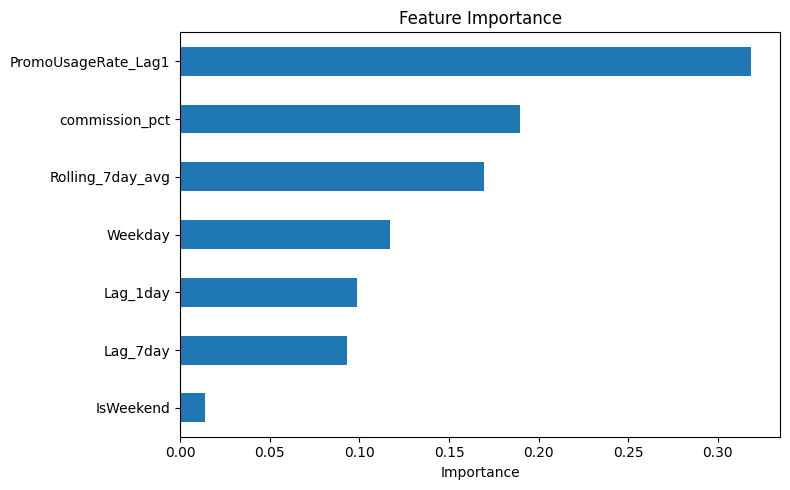

In [52]:
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)

importances.plot(kind='barh', figsize=(8,5), title='Feature Importance')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

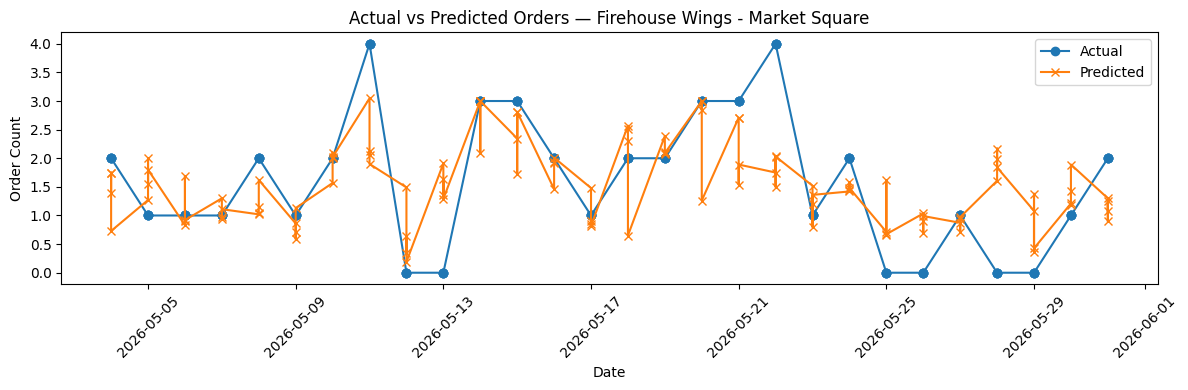

In [51]:
results = test[['Restaurant Name', 'Date', 'OrderCount']].copy()
results['Predicted'] = model_predictions

sample_restaurant = results['Restaurant Name'].iloc[0]
plot_data = results[results['Restaurant Name'] == sample_restaurant].sort_values('Date')

plt.figure(figsize=(12,4))
plt.plot(plot_data['Date'], plot_data['OrderCount'], label='Actual', marker='o')
plt.plot(plot_data['Date'], plot_data['Predicted'], label='Predicted', marker='x')
plt.title(f'Actual vs Predicted Orders — {sample_restaurant}')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [53]:
results['Error'] = results['OrderCount'] - results['Predicted']
results['AbsError'] = results['Error'].abs()

print("Largest errors (model most wrong):")
print(results.sort_values('AbsError', ascending=False).head(10))

Largest errors (model most wrong):
                                Restaurant Name       Date  OrderCount  \
4359         The Breakfast Table - Business Bay 2026-05-12           5   
4871                  Urban Pizza Co - Old Town 2026-05-27           5   
4675        Cloud Nine Bakery - Harbor District 2026-05-21           4   
4430  Charcoal Chicken House - Cultural Quarter 2026-05-14           4   
4667        Cloud Nine Bakery - Harbor District 2026-05-21           4   
4999                    Sushi Circle - Lakeside 2026-05-30           4   
4674        Cloud Nine Bakery - Harbor District 2026-05-21           4   
4475         The Breakfast Table - Business Bay 2026-05-15           3   
4686  Charcoal Chicken House - Cultural Quarter 2026-05-21           4   
4655        Cloud Nine Bakery - Harbor District 2026-05-21           4   

      Predicted   Error  AbsError  
4359     0.8180  4.1820    4.1820  
4871     1.0275  3.9725    3.9725  
4675     0.7790  3.2210    3.2210  
4430  

In [54]:
error_by_restaurant = results.groupby('Restaurant Name')['AbsError'].mean().sort_values(ascending=False)
print(error_by_restaurant)

Restaurant Name
Cloud Nine Bakery - Harbor District          0.939455
Urban Pizza Co - Old Town                    0.810562
The Breakfast Table - Business Bay           0.797197
Urban Pizza Co - Downtown                    0.724190
Firehouse Wings - Market Square              0.679019
Charcoal Chicken House - Cultural Quarter    0.670485
Sushi Circle - Lakeside                      0.645602
Taco Fiesta - Market Square                  0.640434
Charcoal Chicken House - Hill Gardens        0.612425
Cloud Nine Bakery - University Area          0.612409
Name: AbsError, dtype: float64


In [55]:
from sklearn.ensemble import GradientBoostingRegressor

In [56]:
feat_a = ['Hour', 'Weekday', 'IsWeekend', 'Lag_1h', 'Lag_24h']
split_date_a = hourly_clean['DateHour'].quantile(0.8, interpolation='nearest')
train_a = hourly_clean[hourly_clean['DateHour'] <= split_date_a]
test_a = hourly_clean[hourly_clean['DateHour'] > split_date_a]

X_train_a, y_train_a = train_a[feat_a], train_a['OrderCount']
X_test_a, y_test_a = test_a[feat_a], test_a['OrderCount']

gb_model_a = GradientBoostingRegressor(random_state=42)
gb_model_a.fit(X_train_a, y_train_a)
gb_preds_a = gb_model_a.predict(X_test_a)
gb_mae_a = mean_absolute_error(y_test_a, gb_preds_a)

print("Random Forest MAE:", model_mae_hourly)
print("Gradient Boosting MAE:", gb_mae_a)

Random Forest MAE: 2.190341247315523
Gradient Boosting MAE: 1.9746547395558605


In [58]:
print(daily_full_clean[feat_b].isna().sum())

Weekday                  0
IsWeekend                0
Lag_1day                 0
Lag_7day                 0
Rolling_7day_avg       245
commission_pct           0
PromoUsageRate_Lag1      0
dtype: int64


In [59]:
daily_full_clean = daily_full_clean.dropna(subset=feat_b).reset_index(drop=True)
print(daily_full_clean.shape)
print(daily_full_clean[feat_b].isna().sum())

(4795, 14)
Weekday                0
IsWeekend              0
Lag_1day               0
Lag_7day               0
Rolling_7day_avg       0
commission_pct         0
PromoUsageRate_Lag1    0
dtype: int64


In [60]:
feat_b = ['Weekday', 'IsWeekend', 'Lag_1day', 'Lag_7day', 'Rolling_7day_avg', 'commission_pct', 'PromoUsageRate_Lag1']
split_date_b = daily_full_clean['Date'].quantile(0.8, interpolation='nearest')
train_b = daily_full_clean[daily_full_clean['Date'] <= split_date_b]
test_b = daily_full_clean[daily_full_clean['Date'] > split_date_b]

X_train_b, y_train_b = train_b[feat_b], train_b['OrderCount']
X_test_b, y_test_b = test_b[feat_b], test_b['OrderCount']

gb_model_b = GradientBoostingRegressor(random_state=42)
gb_model_b.fit(X_train_b, y_train_b)
gb_preds_b = gb_model_b.predict(X_test_b)
gb_mae_b = mean_absolute_error(y_test_b, gb_preds_b)

print("Random Forest MAE:", model_mae)
print("Gradient Boosting MAE:", gb_mae_b)

Random Forest MAE: 0.7135857385811468
Gradient Boosting MAE: 0.7177803114754184


# Food Delivery Demand Forecasting Using Machine Learning

## Project Overview

This project explores how historical food delivery order data can be used to predict future demand. I worked on two forecasting tasks: predicting hourly order volume across the entire platform and predicting daily order volume for the ten busiest restaurants.

The project started with analyzing ordering patterns and understanding how demand changes over time. I then used these patterns to build forecasting models and compared their predictions with actual order counts.

Since the original company data was confidential, I used a synthetic dataset designed to represent similar food delivery patterns.

## Project Objectives

- Explore order patterns across different hours, weekdays, dates, and restaurants.
- Identify useful features for predicting future order volumes.
- Build baseline forecasting methods for comparison.
- Train and compare Random Forest and Gradient Boosting regression models.
- Evaluate predictions using Mean Absolute Error (MAE).
- Examine prediction errors to understand where and why the models perform poorly.

## Dataset

The dataset contains approximately 25,000 synthetic order records covering 150 days of food delivery activity.

It includes order timestamps, restaurant information, and promotional usage data. These records were used to examine both platform-wide demand and individual restaurant ordering patterns.

## Forecasting Approaches

This project covers two separate forecasting tasks.

**1. Citywide Hourly Demand Forecasting**

The first task predicts the total number of orders received across the platform in a particular hour.

I grouped individual order records into hourly intervals and examined how order volume changes throughout the day and across different dates. The resulting dataset was used to train models that predict hourly demand based on historical patterns and time-related features.

**2. Restaurant-Level Daily Demand Forecasting**

The second task predicts the number of orders received by each of the ten busiest restaurants on a particular day.

During the initial analysis, I found that restaurant-level hourly data was too sparse for meaningful forecasting. Approximately 97.74% of possible restaurant-hour combinations had zero orders. I therefore changed the forecasting interval from hourly to daily and focused on the ten restaurants with the highest order volumes.

## Methodology

Both forecasting tasks followed a similar workflow:

1. **Data Exploration:** Examined the dataset, checked its structure, and analyzed order distribution across different time periods and restaurants.
2. **Data Preprocessing:** Converted timestamps into datetime format, handled missing values, and prepared the data for analysis.
3. **Feature Engineering:** Extracted features such as hour of day and day of week. I also created lag features and rolling averages to include information from previous periods.
4. **Train-Test Split:** Used a chronological split, training the models on earlier observations and evaluating them on later observations.
5. **Baseline Forecasting:** Created simple forecasting methods using previous order counts as reference predictions.
6. **Model Training:** Trained Random Forest Regressor and Gradient Boosting Regressor models.
7. **Model Evaluation:** Compared the models against their respective baselines using Mean Absolute Error.
8. **Error Analysis:** Examined actual and predicted order counts, feature importance, and periods with larger prediction errors.

## Models and Evaluation

I used two tree-based regression algorithms:

- **Random Forest Regressor:** Combines predictions from multiple decision trees to estimate order demand.
- **Gradient Boosting Regressor:** Builds decision trees sequentially, with each new tree attempting to reduce the errors made by previous trees.

Mean Absolute Error (MAE) was used to evaluate model performance. It measures the average absolute difference between predicted and actual order counts, with lower values indicating smaller prediction errors.

## Results and Observations

The models performed differently across the two forecasting tasks.

For citywide hourly forecasting, Gradient Boosting achieved the lowest MAE of 1.97, compared with 2.19 for Random Forest and 4.85 for the baseline.

For restaurant-level daily forecasting, Random Forest achieved an MAE of 0.714, slightly outperforming Gradient Boosting at 0.718 and the baseline at 1.25.

The analysis also showed that hour of day was the most influential feature in citywide forecasting, while the previous day's promotional usage rate was the most influential feature in restaurant-level forecasting.

Error analysis showed that both forecasting tracks had their largest prediction errors around the same two dates, May 21–22, even though they used different time granularities and feature sets. I checked the synthetic data generation logic to see whether these dates were associated with any deliberately introduced events or patterns, but found none. The errors therefore appear more likely to result from random variation in the generated data than from a specific event. With real operational data, a similar pattern would be worth investigating further by checking for possible factors such as holidays, weather conditions, or platform outages.

During model development, I identified a data leakage issue involving promotional usage data. The initial feature used information from the same day being predicted, which would not be available in a real forecasting scenario. I corrected this by using the previous day's promotional usage rate instead and retrained the model.

## Limitations

The project uses synthetic data rather than actual company order records, so the results should not be treated as evidence of real-world forecasting performance.

The models were evaluated on a held-out period from the same dataset and have not been tested on an independent real-world dataset. They also do not account for external factors such as holidays, special events, weather conditions, or unexpected changes in customer behavior.

The forecasting models estimate expected order volume based on historical patterns. They do not measure the causal effect of promotional campaigns or other business decisions.
